<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-scientific-discovery/blob/main/notebooks/lecture-03/cam-cifar10.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

<hr/>
# Deep Learning for Scientific Discovery
**Author:** Marcin Płodzień
<hr/>

# Class activation maps on CIFAR-10

A convolutional neural network (CNN) that ends with global average pooling (GAP) and a single dense layer can show where in an image the evidence for each class lies. The picture that shows it is the class activation map (CAM) of B. Zhou, A. Khosla, A. Lapedriza, A. Oliva and A. Torralba, *Learning Deep Features for Discriminative Localization*, CVPR 2016, [arXiv:1512.04150](https://arxiv.org/abs/1512.04150). The lecture on CNNs shows these maps for a network with six convolutional layers trained on the CIFAR-10 photographs, which reaches $87.6\%$ test accuracy. The data, the network, its training, the trained parameters and every CAM figure of those slides are collected here, together with a numerical check of the identity on which the method rests.

The stored parameters reproduce the figures exactly; retraining is possible with one switch and takes about twenty minutes on a laptop processor (central processing unit, CPU).

In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = ""      # no graphics card visible: everything runs on the CPU

import time, pickle, tarfile, shutil, urllib.request
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import Image, display

torch.set_num_threads(min(8, os.cpu_count()))   # at most 8 CPU threads
plt.rcParams.update({"font.size": 15, "axes.titlesize": 16, "axes.labelsize": 15, "xtick.labelsize": 13,
                     "ytick.labelsize": 13, "legend.fontsize": 13, "figure.titlesize": 17})
UJBlue, UJNavy, DSOrange, UJGray, UJLight = "#005CA7", "#002B5C", "#D35A05", "#5A6270", "#E6EEF7"

DATA, RESULTS = "data", "results"
os.makedirs(DATA, exist_ok=True); os.makedirs(RESULTS, exist_ok=True)
SLIDE_FIGS = os.path.join("..", "beamer", "figures")     # figures used on the lecture slides
CODE_DIR = os.path.join("..", "code", "cam_cifar10")      # original training script and its log
print("PyTorch", torch.__version__, "| NumPy", np.__version__, "| matplotlib", matplotlib.__version__,
      "| threads:", torch.get_num_threads(), "| CUDA available:", torch.cuda.is_available())

PyTorch 2.9.0+cpu | NumPy 2.1.3 | matplotlib 3.10.8 | threads: 8 | CUDA available: False


## The CIFAR-10 data set

CIFAR-10 was collected by A. Krizhevsky, *Learning Multiple Layers of Features from Tiny Images*, technical report, University of Toronto, 2009 ([PDF](https://www.cs.toronto.edu/~kriz/learning-features-2009-TR.pdf), data at <https://www.cs.toronto.edu/~kriz/cifar.html>). It is a labelled subset of the "80 million tiny images", photographs found on the internet and reduced to $32\times32$ pixels. The name refers to the Canadian Institute for Advanced Research (CIFAR), which funded the work, and to the ten classes: airplane, automobile, bird, cat, deer, dog, frog, horse, ship and truck. The classes are mutually exclusive; "automobile" covers cars and similar vehicles, "truck" only large trucks.

One sample $x_i$ is a colour photograph in the red-green-blue (RGB) encoding: three $32\times32$ arrays of intensities, one per colour channel, stored as unsigned 8-bit integers (`uint8`, whole numbers $0\dots255$; $0$ is no light in that channel, $255$ the maximum). Its label $y_i\in\{0,\dots,9\}$ is the index of the class. The data set has $50\,000$ training and $10\,000$ test images, $5000$ and $1000$ per class.

The "python version" of the data set consists of pickled batches. Each holds `data`, an array of shape $(10000, 3072)$ with the 1024 red values of an image followed by 1024 green and 1024 blue values, and `labels`. The batches are read from the Keras cache if it exists, otherwise the archive (163 MB) is downloaded once into `data/`.

In [2]:
CIFAR_URL = "https://www.cs.toronto.edu/~kriz/cifar-10-python.tar.gz"
CIFAR_CANDIDATES = [os.path.expanduser("~/.keras/datasets/cifar-10-batches-py"), os.path.join(DATA, "cifar-10-batches-py")]

def cifar_dir():
    for d in CIFAR_CANDIDATES:
        if os.path.exists(os.path.join(d, "test_batch")): return d
    tgz = os.path.join(DATA, "cifar-10-python.tar.gz")
    print("downloading CIFAR-10 (163 MB) ...")
    urllib.request.urlretrieve(CIFAR_URL, tgz)
    with tarfile.open(tgz) as t: t.extractall(DATA, filter="data")
    return os.path.join(DATA, "cifar-10-batches-py")

def load(D, name):
    # one pickled batch -> images (N, 3, 32, 32) uint8 and labels (N,)
    with open(f"{D}/{name}", "rb") as f:
        d = pickle.load(f, encoding="bytes")
    return d[b"data"].reshape(-1, 3, 32, 32), np.array(d[b"labels"])

D_CIFAR = cifar_dir()
xs, ys = zip(*[load(D_CIFAR, f"data_batch_{i}") for i in range(1, 6)])
Xtr, ytr = np.concatenate(xs), np.concatenate(ys)
Xte, yte = load(D_CIFAR, "test_batch")
with open(f"{D_CIFAR}/batches.meta", "rb") as f:
    CLASSES = [c.decode() for c in pickle.load(f, encoding="bytes")[b"label_names"]]
assert Xtr.shape == (50000, 3, 32, 32) and Xte.shape == (10000, 3, 32, 32)
print("CIFAR-10 from", D_CIFAR)
print("training:", Xtr.shape, Xtr.dtype, " test:", Xte.shape, " values", Xtr.min(), "...", Xtr.max())
print("images per class, training:", np.bincount(ytr), " test:", np.bincount(yte))
print("classes:", CLASSES)
print(f"\nfirst training image, label {ytr[0]} = {CLASSES[ytr[0]]}; red channel, top-left 4 x 4 pixels:")
print(Xtr[0, 0, :4, :4])

CIFAR-10 from /home/marcin/.keras/datasets/cifar-10-batches-py
training: (50000, 3, 32, 32) uint8  test: (10000, 3, 32, 32)  values 0 ... 255
images per class, training: [5000 5000 5000 5000 5000 5000 5000 5000 5000 5000]  test: [1000 1000 1000 1000 1000 1000 1000 1000 1000 1000]
classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

first training image, label 6 = frog; red channel, top-left 4 x 4 pixels:
[[ 59  43  50  68]
 [ 16   0  18  51]
 [ 25  16  49  83]
 [ 33  38  87 106]]


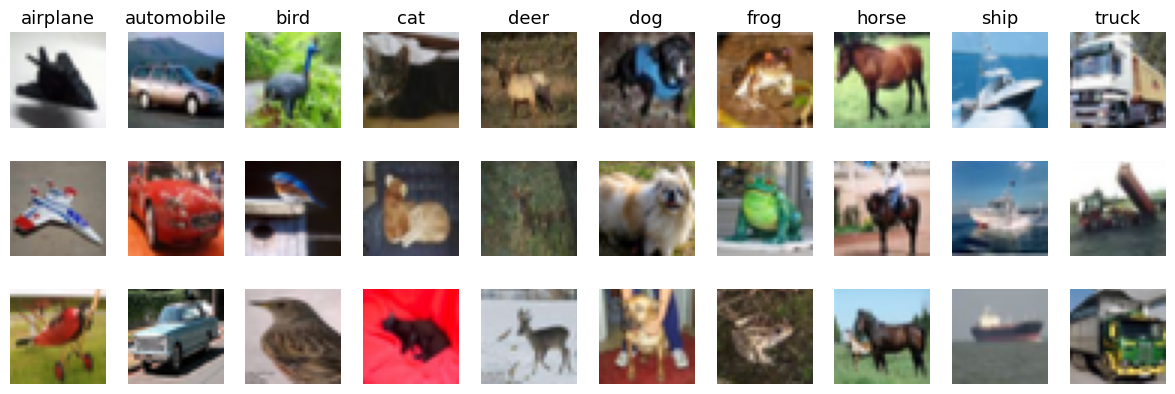

In [3]:
fig, axes = plt.subplots(3, 10, figsize=(12, 4.4))
for c in range(10):
    for r, i in enumerate(np.flatnonzero(ytr == c)[:3]):
        axes[r, c].imshow(Xtr[i].transpose(1, 2, 0))          # (3, 32, 32) -> (32, 32, 3) for plotting
        axes[r, c].axis("off")
    axes[0, c].set_title(CLASSES[c], fontsize=13)
fig.tight_layout(); fig.savefig(f"{RESULTS}/cam_cifar_examples.png", dpi=150); plt.show()

The first three training images of every class show what the network must cope with: objects at different sizes and positions, partly cut by the frame, on varied backgrounds, at a resolution where a cat and a dog differ in a few dozen pixels.

Before training, each colour channel $c$ is standardised with the mean $\mu_c$ and the standard deviation $\sigma_c$ of the training pixels, measured on the scale $[0,1]$,
$$x \leftarrow \frac{x/255-\mu_c}{\sigma_c}. \tag{1}$$
The inputs then have mean zero and unit variance in every channel, and the same $\mu_c,\sigma_c$ (stored with the trained parameters) are applied to the test images.

In [4]:
mean = Xtr.reshape(-1, 3, 1024).mean((0, 2)) / 255; std = Xtr.reshape(-1, 3, 1024).std((0, 2)) / 255
def prep(X, mean, std):
    return (torch.tensor(X, dtype=torch.float32) / 255 - torch.tensor(mean, dtype=torch.float32)[:, None, None]) \
           / torch.tensor(std, dtype=torch.float32)[:, None, None]
print("mu_c    (R, G, B):", np.round(mean, 4))
print("sigma_c (R, G, B):", np.round(std, 4))

mu_c    (R, G, B): [0.4914 0.4822 0.4465]
sigma_c (R, G, B): [0.247  0.2435 0.2616]


## The network

The network has a convolutional body of three blocks. A block is two convolutional layers with $3\times3$ kernels and padding 1, so that the height and width of the maps do not change; each convolution is followed by batch normalisation and the rectified linear unit (ReLU). A convolutional layer with $C_\text{in}$ input and $C_\text{out}$ output channels computes, for output channel $o$ at position $(x,y)$,
$$h_o(x,y) = b_o + \sum_{i=1}^{C_\text{in}}\sum_{u,v=-1}^{1} K_{o,i}(u,v)\, x_i(x+u,\,y+v), \tag{2}$$
with $3\times3$ kernels $K_{o,i}$ and biases $b_o$, so that it has
$$C_\text{out}\,(9\,C_\text{in}+1) \tag{3}$$
parameters. Batch normalisation (BN; S. Ioffe and C. Szegedy, ICML 2015, [arXiv:1502.03167](https://arxiv.org/abs/1502.03167)) standardises every channel over the mini-batch $B$ and rescales it with a trainable scale $\gamma$ and shift $\beta$,
$$\hat h = \frac{h-\mu_B}{\sqrt{\sigma_B^2+\epsilon}},\qquad h \leftarrow \gamma\,\hat h+\beta, \tag{4}$$
which adds $2\,C_\text{out}$ trainable parameters per layer. During training $\mu_B,\sigma_B^2$ are the mean and variance of the current mini-batch; the layer also keeps running averages of them, which replace the batch statistics at test time. Those running averages are buffers, not parameters, and do not enter the parameter count. The ReLU is
$$\mathrm{ReLU}(z)=\max(0,z). \tag{5}$$

Max pooling with a $2\times2$ window halves the height and width after the first and the second block, so the maps go from $32\times32$ to $16\times16$ to $8\times8$. The third block ends with $K=128$ feature maps $f_k$ of $8\times8$ positions. Global average pooling replaces each map by its mean $F_k$, and one dense layer maps the 128 means to the 10 class scores. The `forward` method returns the scores and, for the class activation maps, the feature maps $f_k$.

In [5]:
# the architecture of ../code/cam_cifar10/net_def.py, unchanged
def block(i, o): return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(),
                                      nn.Conv2d(o, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU())
class Net(nn.Module):
    def __init__(s):
        super().__init__()
        s.features = nn.Sequential(block(3, 32), nn.MaxPool2d(2), block(32, 64), nn.MaxPool2d(2), block(64, 128))  # -> 128 x 8 x 8
        s.fc = nn.Linear(128, 10)
    def forward(s, x):
        f = s.features(x)
        return s.fc(f.mean((2, 3))), f      # global average pooling, then dense

n_params = sum(p.numel() for p in Net().parameters())
print("parameters:", n_params)

parameters: 289194


The library `torchinfo` sends one input through the model and lists every layer with the shape of its output and its number of parameters. Global average pooling does not appear in the list: it is the operation `f.mean((2, 3))` inside `forward`, not a module.

In [6]:
import importlib.util, subprocess, sys
if importlib.util.find_spec("torchinfo") is None or importlib.util.find_spec("torchview") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "torchinfo", "torchview", "graphviz"])   # e.g. in Google Colab
from torchinfo import summary
from torchview import draw_graph

info = summary(Net(), input_data=torch.zeros(1, 3, 32, 32), col_names=("output_size", "num_params"), depth=3, verbose=0)
print(info)

Layer (type:depth-idx)                   Output Shape              Param #
Net                                      [1, 10]                   --
├─Sequential: 1-1                        [1, 128, 8, 8]            --
│    └─Sequential: 2-1                   [1, 32, 32, 32]           --
│    │    └─Conv2d: 3-1                  [1, 32, 32, 32]           896
│    │    └─BatchNorm2d: 3-2             [1, 32, 32, 32]           64
│    │    └─ReLU: 3-3                    [1, 32, 32, 32]           --
│    │    └─Conv2d: 3-4                  [1, 32, 32, 32]           9,248
│    │    └─BatchNorm2d: 3-5             [1, 32, 32, 32]           64
│    │    └─ReLU: 3-6                    [1, 32, 32, 32]           --
│    └─MaxPool2d: 2-2                    [1, 32, 16, 16]           --
│    └─Sequential: 2-3                   [1, 64, 16, 16]           --
│    │    └─Conv2d: 3-7                  [1, 64, 16, 16]           18,496
│    │    └─BatchNorm2d: 3-8             [1, 64, 16, 16]           128
│    │

With equation (3), the first convolution has $32\,(9\cdot3+1)=896$ parameters and the second one of the last block $128\,(9\cdot128+1)=147\,584$; the six convolutions hold almost all parameters, the dense layer only $128\cdot10+10=1290$. The library `torchview` draws the same forward pass as a graph of modules, with the input and output shapes of each.

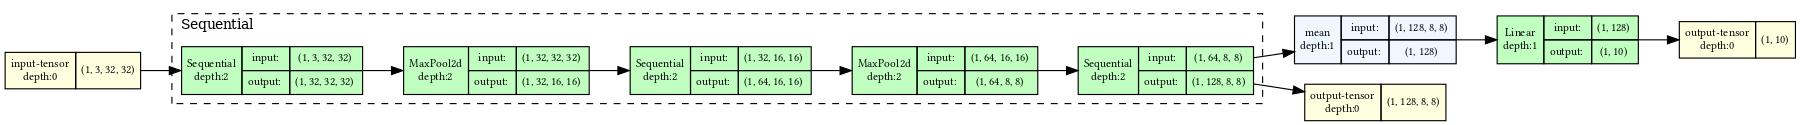

In [7]:
graph = draw_graph(Net(), input_data=torch.zeros(1, 3, 32, 32), expand_nested=True, depth=2, graph_dir="LR")
graph.visual_graph.graph_attr.update(dpi="150")
graph.visual_graph.render(f"{RESULTS}/cam_cifar_torchview", format="png", cleanup=True)
display(Image(filename=f"{RESULTS}/cam_cifar_torchview.png"))

A compact picture draws one block per stage of the network. The output shapes and parameter counts in it are read from the model: forward hooks, functions that PyTorch calls after a module has computed its output, record the shape at the end of every stage, and the parameters are counted per module. The total must equal the one of `torchinfo`.

input image                      (3, 32, 32)             0
conv block 1 2 x conv BN, ReLU   (32, 32, 32)       10,272
max pool 2 x 2                   (32, 16, 16)            0
conv block 2 2 x conv BN, ReLU   (64, 16, 16)       55,680
max pool 2 x 2                   (64, 8, 8)              0
conv block 3 2 x conv BN, ReLU   (128, 8, 8)       221,952
global average pooling           (128,)                  0
dense 128 -> 10                  (10,)               1,290
total 289194 = torchinfo 289194


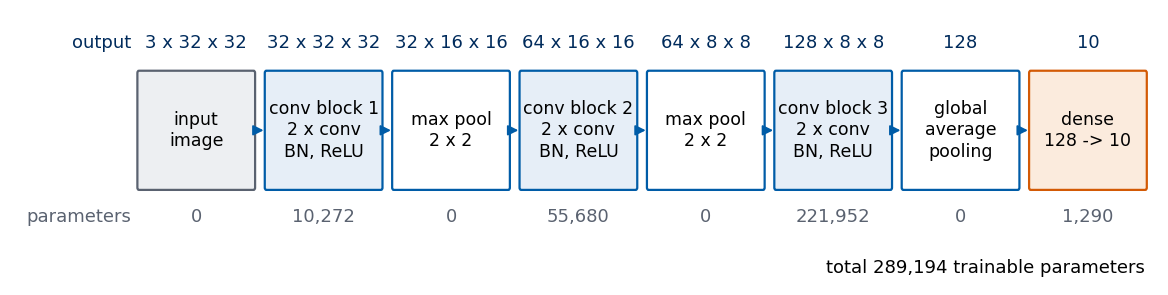

In [8]:
net0 = Net()
stages = [("input", None)] + [(n, m) for n, m in zip(["conv block 1\n2 x conv\nBN, ReLU", "max pool\n2 x 2",
                                                       "conv block 2\n2 x conv\nBN, ReLU", "max pool\n2 x 2",
                                                       "conv block 3\n2 x conv\nBN, ReLU"], net0.features)]
shapes = {}
hooks = [m.register_forward_hook(lambda mod, inp, out, k=k: shapes.__setitem__(k, tuple(out.shape[1:])))
         for k, (_, m) in enumerate(stages) if m is not None]
hooks.append(net0.fc.register_forward_hook(lambda mod, inp, out: shapes.update(gap=tuple(inp[0].shape[1:]), fc=tuple(out.shape[1:]))))
with torch.no_grad(): net0(torch.zeros(1, 3, 32, 32))
for h in hooks: h.remove()

count = lambda m: sum(p.numel() for p in m.parameters())
rows = [("input\nimage", (3, 32, 32), 0)]
rows += [(name, shapes[k], count(m)) for k, (name, m) in enumerate(stages) if m is not None]
rows += [("global\naverage\npooling", shapes["gap"], 0), ("dense\n128 -> 10", shapes["fc"], count(net0.fc))]
assert sum(r[2] for r in rows) == info.total_params == n_params
for name, shp, p in rows: print(f"{name.replace(chr(10), ' '):32s} {str(shp):16s} {p:8,d}")
print("total", sum(r[2] for r in rows), "= torchinfo", info.total_params)

def shape_str(s): return " x ".join(map(str, s))
fig, ax = plt.subplots(figsize=(12, 3.2))
n, w, gap_ = len(rows), 1.42, 0.16
for j, (name, shp, p) in enumerate(rows):
    x0 = j * (w + gap_)
    kind = "io" if j in (0, n - 1) else ("conv" if "conv" in name else "op")
    fc_, ec = {"io": ("#EDEFF2", UJGray), "conv": (UJLight, UJBlue), "op": ("white", UJBlue)}[kind]
    if j == n - 1: fc_, ec = "#FBEBDD", DSOrange
    ax.add_patch(FancyBboxPatch((x0, 0.0), w, 1.0, boxstyle="round,pad=0.02", fc=fc_, ec=ec, lw=1.6))
    ax.text(x0 + w / 2, 0.5, name, ha="center", va="center", fontsize=12.5, linespacing=1.25)
    ax.text(x0 + w / 2, 1.18, shape_str(shp), ha="center", va="bottom", fontsize=13, color=UJNavy)
    ax.text(x0 + w / 2, -0.18, f"{p:,d}" if p else "0", ha="center", va="top", fontsize=13, color=UJGray)
    if j < n - 1: ax.annotate("", xy=(x0 + w + gap_, 0.5), xytext=(x0 + w, 0.5), arrowprops=dict(arrowstyle="-|>", color=UJBlue, lw=1.4))
ax.text(-0.1, 1.18, "output", ha="right", va="bottom", fontsize=13, color=UJNavy)
ax.text(-0.1, -0.18, "parameters", ha="right", va="top", fontsize=13, color=UJGray)
ax.text(n * (w + gap_) - gap_, -0.62, f"total {sum(r[2] for r in rows):,d} trainable parameters", ha="right", va="top", fontsize=13)
ax.set_xlim(-1.6, n * (w + gap_)); ax.set_ylim(-0.85, 1.55); ax.axis("off")
fig.tight_layout(); fig.savefig(f"{RESULTS}/cam_cifar_arch.png", dpi=150); plt.show()

## Training

The network is trained for 12 epochs (passes through the $50\,000$ training images) in mini-batches of 128 images with the categorical cross-entropy
$$L = -\frac{1}{|B|}\sum_{i\in B}\log q_{y_i}(x_i), \tag{6}$$
where $q_{y_i}(x_i)$ is the softmax probability that the network gives to the true class $y_i$ of image $x_i$ (equation (10)). The optimiser is Adam (adaptive moment estimation; D. P. Kingma and J. Ba, ICLR 2015, [arXiv:1412.6980](https://arxiv.org/abs/1412.6980)), which scales each parameter's step by running estimates of the mean and the magnitude of its gradient.

The learning rate $\eta$ follows the one-cycle schedule of L. N. Smith and N. Topin ([arXiv:1708.07120](https://arxiv.org/abs/1708.07120)), `OneCycleLR` in PyTorch with its default settings. Over the first $30\%$ of the $T=12\cdot391=4692$ steps it rises from $\eta_\text{max}/25$ to $\eta_\text{max}=3\cdot10^{-3}$, and over the remaining steps it falls to $\eta_\text{max}/(25\cdot10^4)$, in both phases along half a cosine: within a phase that goes from $\eta_a$ to $\eta_b$, at fraction $s\in[0,1]$ of the phase,
$$\eta(s) = \eta_b + \frac{\eta_a-\eta_b}{2}\,\bigl(1+\cos\pi s\bigr). \tag{7}$$
The large rates in the middle of training move the parameters quickly; the small rates at the end let them settle. In the same cycle the schedule moves Adam's first-moment coefficient $\beta_1$ in the opposite direction, between $0.95$ and $0.85$.

Data augmentation shows the network a modified copy of each mini-batch. Every image is mirrored left to right with probability $1/2$, and the whole mini-batch is shifted by a random offset of up to 4 pixels in each direction: the images are padded with 4 mirrored pixels on every side (reflect padding) and one $32\times32$ window is cut out at a random position, the same for all images of the mini-batch. A cat mirrored or shifted by a few pixels is still a cat, so the network learns features that do not depend on these changes, and it cannot memorise the exact pixels of the training images.

The random seeds fix the initial parameters (`torch.manual_seed(0)`) and the shifts (`np.random.seed(0)`). The training code is the script `../code/cam_cifar10/train_cam_cifar.py`. With `TRAIN = False` it is not run, and the parameters stored after the original run are loaded instead. With `TRAIN = True` the network is trained again, which took $1252$ s (about 21 min) for the original run according to the times in its log; the new parameters are saved under a separate name and used in all later cells. A retrained network can reach a slightly different accuracy and give slightly different maps, because the order of floating-point operations depends on the number of threads and on the library version.

In [9]:
TRAIN = False                                         # True: train again (about 20 min on a laptop CPU)
CKPT_ORIG = os.path.join(CODE_DIR, "cifar_gap_cnn.pt")
CKPT = os.path.join(RESULTS, "cam_cifar_gap_cnn.pt")   # parameters of the original run
if not os.path.exists(CKPT): shutil.copy(CKPT_ORIG, CKPT)
EPOCHS = 12

def train_network(path, epochs=EPOCHS):
    torch.manual_seed(0); np.random.seed(0)
    Xtr_t, Xte_t = prep(Xtr, mean, std), prep(Xte, mean, std); ytr_t, yte_t = torch.tensor(ytr), torch.tensor(yte)
    net = Net(); opt = torch.optim.Adam(net.parameters(), 1e-3)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, 3e-3, epochs=epochs, steps_per_epoch=(50000 + 127) // 128)
    def augment(x):
        flip = torch.rand(x.shape[0]) < 0.5; x = x.clone(); x[flip] = x[flip].flip(3)
        x = F.pad(x, (4, 4, 4, 4), mode="reflect"); i, j = np.random.randint(0, 9, 2)
        return x[:, :, i:i + 32, j:j + 32]
    def accuracy(X, y):
        net.eval(); c = 0
        with torch.no_grad():
            for k in range(0, len(X), 1000): c += (net(X[k:k + 1000])[0].argmax(1) == y[k:k + 1000]).sum().item()
        return c / len(X)
    for ep in range(epochs):
        net.train(); t = time.time(); perm = torch.randperm(50000)
        for k in range(0, 50000, 128):
            idx = perm[k:k + 128]; loss = F.cross_entropy(net(augment(Xtr_t[idx]))[0], ytr_t[idx])
            opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        print(f"epoch {ep + 1}: test accuracy {accuracy(Xte_t, yte_t):.3f}  ({time.time() - t:.0f} s)", flush=True)
    torch.save({"state": net.state_dict(), "mean": mean, "std": std, "classes": CLASSES}, path)
    print("final test accuracy", accuracy(Xte_t, yte_t))

if TRAIN:
    CKPT = os.path.join(RESULTS, "cam_cifar_gap_cnn_retrained.pt")
    train_network(CKPT)

ck = torch.load(CKPT, weights_only=False)
net = Net(); net.load_state_dict(ck["state"]); net.eval()
classes = ck["classes"]
assert classes == CLASSES and np.allclose(ck["mean"], mean) and np.allclose(ck["std"], std)
print("parameters loaded from", CKPT)

parameters loaded from results/cam_cifar_gap_cnn.pt


The test accuracy is the fraction of the $10\,000$ test images whose largest class score belongs to the true class. It is evaluated as in the training script, in batches of 1000 images with the network in evaluation mode (batch normalisation with its running averages).

In [10]:
Xte_t, yte_t = prep(Xte, ck["mean"], ck["std"]), torch.tensor(yte)
correct = 0
with torch.no_grad():
    for k in range(0, len(Xte_t), 1000): correct += (net(Xte_t[k:k + 1000])[0].argmax(1) == yte_t[k:k + 1000]).sum().item()
test_acc = correct / len(Xte_t)
print("test accuracy", test_acc, f"({correct} of {len(Xte_t)} test images)")
if not TRAIN: assert test_acc == 0.8756, test_acc     # final line of ../code/cam_cifar10/train.log

test accuracy 0.8756 (8756 of 10000 test images)


The stored parameters give the accuracy $0.8756$ of the last line of the training log. The test accuracy after each epoch was printed by the training script into `../code/cam_cifar10/train.log`; the twelve values and the times per epoch are copied from that file and plotted. The learning rate of equation (7) is obtained by running the same `OneCycleLR` schedule on a dummy optimiser.

training time in the log: 1252 s


learning rate: start 1.20e-04, maximum 3.00e-03 at step 1407, end 1.20e-08


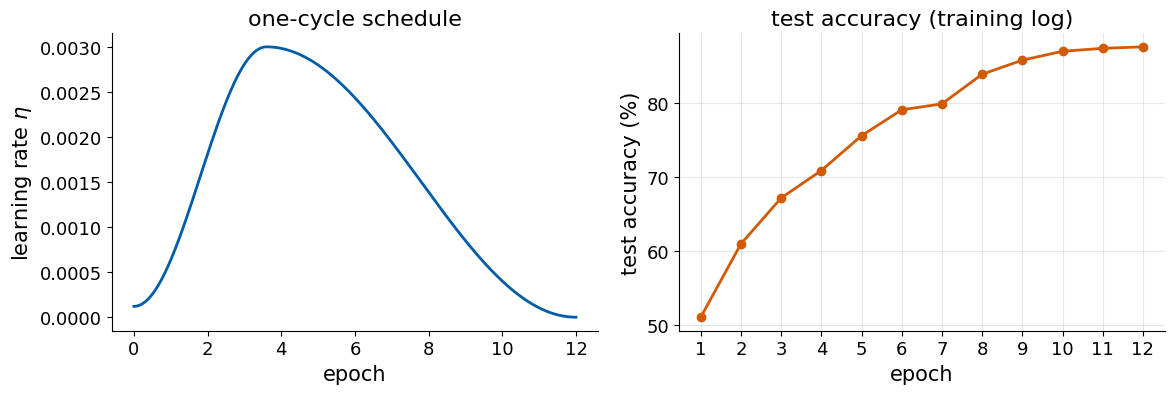

In [11]:
# from ../code/cam_cifar10/train.log (original run, 16 threads)
LOG_TEST_ACC = [0.511, 0.610, 0.672, 0.709, 0.756, 0.791, 0.799, 0.839, 0.858, 0.870, 0.874, 0.876]
LOG_SECONDS = [86, 129, 117, 117, 84, 84, 98, 149, 122, 82, 88, 96]
print("training time in the log:", sum(LOG_SECONDS), "s")

opt_ = torch.optim.Adam([torch.zeros(1, requires_grad=True)], 1e-3)
steps = (50000 + 127) // 128
sch_ = torch.optim.lr_scheduler.OneCycleLR(opt_, 3e-3, epochs=EPOCHS, steps_per_epoch=steps)
lrs = []
for _ in range(EPOCHS * steps):
    lrs.append(opt_.param_groups[0]["lr"]); opt_.step(); sch_.step()
print(f"learning rate: start {lrs[0]:.2e}, maximum {max(lrs):.2e} at step {int(np.argmax(lrs))}, end {lrs[-1]:.2e}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].plot(np.arange(len(lrs)) / steps, lrs, color=UJBlue, lw=2)
ax[0].set_xlabel("epoch"); ax[0].set_ylabel(r"learning rate $\eta$"); ax[0].set_title("one-cycle schedule")
ax[1].plot(range(1, EPOCHS + 1), 100 * np.array(LOG_TEST_ACC), "o-", color=DSOrange, lw=2)
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("test accuracy (%)"); ax[1].set_title("test accuracy (training log)")
ax[1].set_xticks(range(1, EPOCHS + 1, 1)); ax[1].grid(alpha=0.3)
for a in ax: a.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); fig.savefig(f"{RESULTS}/cam_cifar_training.png", dpi=150); plt.show()

The accuracy rises fastest in the first epochs, while the learning rate is still increasing, and keeps improving during the long decrease of the rate: the last four epochs, with small rates, add almost four percentage points.

The confusion matrix counts, for every true class (row), how many test images were assigned to each class (column). It is computed with `sklearn.metrics.confusion_matrix`, and its diagonal gives the accuracy per class.

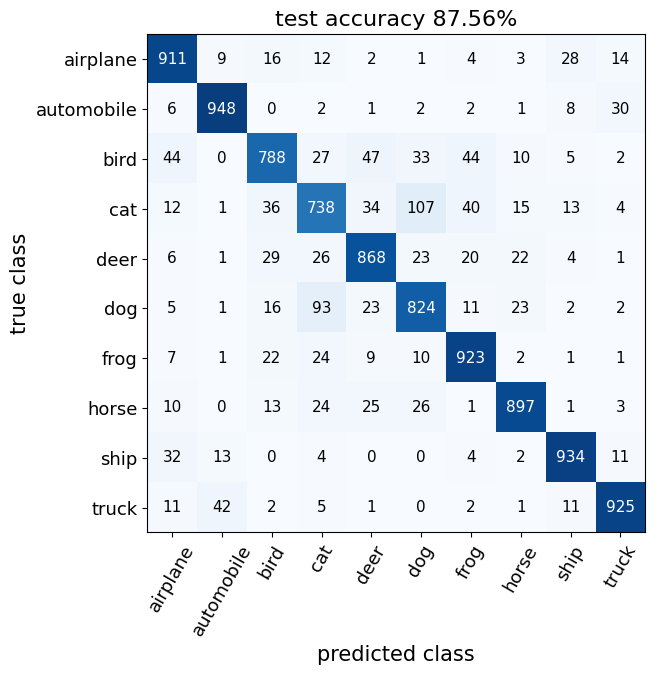

cat          73.8%
bird         78.8%
dog          82.4%
deer         86.8%
horse        89.7%
airplane     91.1%
frog         92.3%
truck        92.5%
ship         93.4%
automobile   94.8%
largest confusion: 107 cat images classified as dog


In [12]:
from sklearn.metrics import confusion_matrix
with torch.no_grad(): pred_all = torch.cat([net(Xte_t[k:k + 1000])[0].argmax(1) for k in range(0, 10000, 1000)]).numpy()
cm = confusion_matrix(yte, pred_all)
assert np.trace(cm) == correct
frac = cm / cm.sum(1, keepdims=True)
fig, ax = plt.subplots(figsize=(8, 7))
ax.imshow(frac, cmap="Blues", vmin=0, vmax=1)
for a in range(10):
    for b in range(10):
        ax.text(b, a, cm[a, b], ha="center", va="center", fontsize=11, color="white" if frac[a, b] > 0.5 else "black")
ax.set_xticks(range(10)); ax.set_xticklabels(CLASSES, rotation=60); ax.set_yticks(range(10)); ax.set_yticklabels(CLASSES)
ax.set_xlabel("predicted class"); ax.set_ylabel("true class"); ax.set_title(f"test accuracy {100 * test_acc:.2f}%")
fig.tight_layout(); fig.savefig(f"{RESULTS}/cam_cifar_confusion.png", dpi=150); plt.show()
for c in np.argsort(np.diag(frac)): print(f"{CLASSES[c]:11s} {100 * frac[c, c]:5.1f}%")
off = cm.copy(); np.fill_diagonal(off, 0); a, b = np.unravel_index(off.argmax(), off.shape)
print(f"largest confusion: {off[a, b]} {CLASSES[a]} images classified as {CLASSES[b]}")

The weakest class is the cat and the largest confusion is between cats and dogs, the two classes that differ least at $32\times32$ pixels; vehicles and the frog are recognised best. The misclassified examples of the CAM section are taken from these confusions.

## Class activation maps

Let $f_k(x,y)$ be the value of the feature map $k=1,\dots,K$, $K=128$, of the last convolutional block at the position $(x,y)$ of the $8\times8$ grid, which has $N=64$ positions. Global average pooling gives one number per map,
$$F_k = \frac{1}{N}\sum_{x,y} f_k(x,y). \tag{8}$$
The dense layer, with weights $w^c_k$ from feature $k$ to class $c$ (in PyTorch `fc.weight[c, k]`) and biases $b_c$ (`fc.bias[c]`), produces the score of class $c$,
$$S_c = \sum_{k=1}^{K} w^c_k\,F_k + b_c, \tag{9}$$
written $z_c$ on some slides; the scores are the logits, the inputs of the softmax that turns them into class probabilities,
$$q_c = \frac{e^{S_c}}{\sum_{j} e^{S_j}}. \tag{10}$$

Inserting equation (8) into equation (9) and exchanging the two finite sums gives
$$S_c = \sum_k w^c_k\,\frac{1}{N}\sum_{x,y} f_k(x,y) + b_c = \frac{1}{N}\sum_{x,y}\,\sum_k w^c_k\,f_k(x,y) + b_c. \tag{11}$$
The inner sum is the class activation map of class $c$,
$$M_c(x,y) = \sum_{k=1}^{K} w^c_k\, f_k(x,y), \tag{12}$$
an $8\times8$ map in which each position carries its contribution to the score of class $c$: positive values are evidence for the class, negative values evidence against it. Equation (11) states that its spatial mean plus the bias is the class score,
$$\frac{1}{N}\sum_{x,y} M_c(x,y) + b_c = S_c. \tag{13}$$
Equation (9) first averages each map and then weights the averages, so the position is lost; equation (12) first weights the maps and adds them, so the position is kept. Both orders give the same score. The map needs no new parameters and no new training: it is computed from the trained feature maps and the weights of the dense layer.

To lay the map over the image it is upsampled from $8\times8$ to the image size by bilinear interpolation and, for display only, rescaled to $[0,1]$,
$$\tilde M_c = \frac{M_c-\min M_c}{\max M_c-\min M_c}. \tag{14}$$
The rescaling removes the absolute values, so a map shows where the evidence is relative to the rest of the image, not how strong it is.

In [13]:
# as in ../code/cam_cifar10/cam_cifar_fig.py and cam_paths_fig.py: all test images in one pass
X, y = Xte, yte                                     # (10000, 3, 32, 32) uint8, (10000,)
Xt = (torch.tensor(X, dtype=torch.float32) / 255 - torch.tensor(ck["mean"], dtype=torch.float32)[:, None, None]) / torch.tensor(ck["std"], dtype=torch.float32)[:, None, None]
with torch.no_grad(): logits, feats = net(Xt)
P = F.softmax(logits, 1); pred = P.argmax(1).numpy()
W = net.fc.weight.detach()
print("feature maps:", tuple(feats.shape), " dense weights:", tuple(W.shape), " test accuracy", float((pred == y).mean()))

feature maps: (10000, 128, 8, 8)  dense weights: (10, 128)  test accuracy 0.8756


For a numerical check of equations (9) and (13) one dog of the test set is chosen: among the correctly classified dogs, sorted by the probability of "dog", the sixth one. The same image appears in all figures of the CAM slides that follow one image.

In [14]:
c = classes.index("dog")
ok = np.where((y == c) & (pred == c))[0]; i = ok[np.argsort(-P[ok, c].numpy())][5]
f = feats[i].numpy(); w = net.fc.weight[c].detach().numpy(); b = float(net.fc.bias[c])
Fk = f.mean((1, 2)); S = float(w @ Fk + b); M = np.tensordot(w, f, 1)
print("image", i, "S_dog from network", float(logits[i, c]), " w.F+b", S, " mean(M)+b", M.mean() + b)
print(f"probability of 'dog': {float(P[i, c]):.4f}")
assert abs(S - float(logits[i, c])) < 1e-3 and abs(M.mean() + b - S) < 1e-3
top = np.argsort(-(w * Fk))[:4]
print("four largest contributions w_k F_k:", [(int(k), round(float(w[k] * Fk[k]), 3)) for k in top])

image 1650 S_dog from network 13.176931381225586  w.F+b 13.176931381225586  mean(M)+b 13.176932
probability of 'dog': 1.0000
four largest contributions w_k F_k: [(40, 1.004), (23, 0.954), (87, 0.876), (70, 0.751)]


/tmp/ipykernel_471583/153760477.py:3: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  f = feats[i].numpy(); w = net.fc.weight[c].detach().numpy(); b = float(net.fc.bias[c])


The score of the network, the sum of equation (9) and the mean of the map in equation (13) agree to the precision of 32-bit floating-point numbers. Two figures show the two orders of the operations for this image. In the first, each of the four maps with the largest contributions $w^{\text{dog}}_k F_k$ is reduced to its mean; in the second, the same maps are multiplied by their weights and added into $M_{\text{dog}}$, which is then enlarged and laid over the image. The CAM figures are made with the default matplotlib settings, as in the original scripts, so that the files agree with the slides.

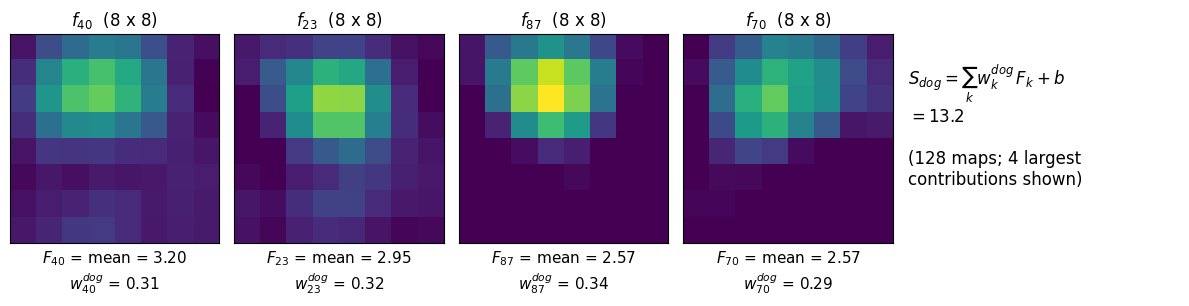

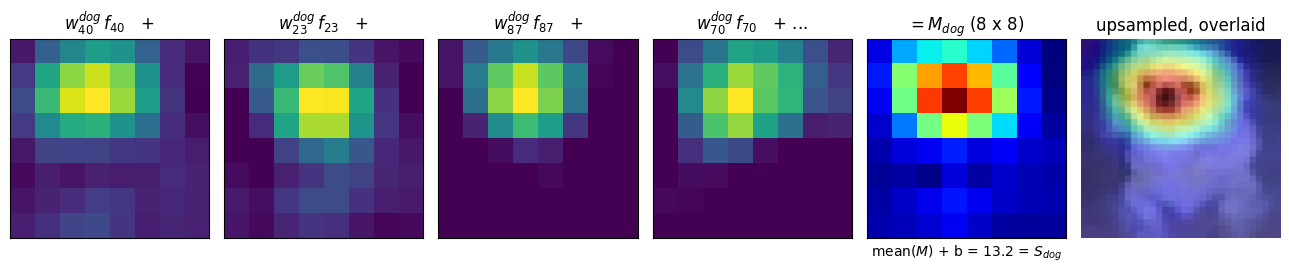

In [15]:
img = X[i].transpose(1, 2, 0)
vmax = max(f[k].max() for k in top)
with plt.style.context("default"):
    # figure A: GAP path
    fig, ax = plt.subplots(1, 5, figsize=(12, 3.0), gridspec_kw={"width_ratios": [1, 1, 1, 1, 1.3]})
    for j, k in enumerate(top):
        ax[j].imshow(f[k], cmap="viridis", vmin=0, vmax=vmax); ax[j].set_xticks([]); ax[j].set_yticks([])
        ax[j].set_title(f"$f_{{{k}}}$  (8 x 8)", fontsize=12)
        ax[j].set_xlabel(f"$F_{{{k}}}$ = mean = {Fk[k]:.2f}\n$w_{{{k}}}^{{dog}}$ = {w[k]:.2f}", fontsize=11)
    ax[4].axis("off")
    ax[4].text(0.0, 0.55, r"$S_{dog}=\sum_k w_k^{dog}\,F_k + b$" + "\n" + f"$= {S:.1f}$" + "\n\n(128 maps; 4 largest\ncontributions shown)",
               fontsize=12, va="center", transform=ax[4].transAxes)
    fig.tight_layout(); fig.savefig(f"{RESULTS}/gen_cam_path_gap.png", dpi=150); plt.show()

    # figure B: CAM path
    fig, ax = plt.subplots(1, 6, figsize=(13, 3.0))
    for j, k in enumerate(top):
        ax[j].imshow(w[k] * f[k], cmap="viridis"); ax[j].set_xticks([]); ax[j].set_yticks([])
        ax[j].set_title(f"$w_{{{k}}}^{{dog}}\\, f_{{{k}}}$" + ("   +" if j < 3 else "   + ..."), fontsize=12)
    ax[4].imshow(M, cmap="jet"); ax[4].set_xticks([]); ax[4].set_yticks([])
    ax[4].set_title(r"$= M_{dog}$ (8 x 8)", fontsize=12)
    ax[4].set_xlabel(f"mean($M$) + b = {M.mean() + b:.1f} = $S_{{dog}}$", fontsize=10)
    up = F.interpolate(torch.tensor(M)[None, None], size=(32, 32), mode="bilinear", align_corners=False)[0, 0].numpy()
    up = (up - up.min()) / (up.max() - up.min())
    ax[5].imshow(img.repeat(4, 0).repeat(4, 1)); ax[5].imshow(np.kron(up, np.ones((4, 4))), cmap="jet", alpha=0.45)
    ax[5].set_title("upsampled, overlaid", fontsize=12); ax[5].axis("off")
    fig.tight_layout(); fig.savefig(f"{RESULTS}/gen_cam_path_map.png", dpi=150); plt.show()

Each of the four maps responds to a different part of the dog, and averaging turns each into a single number: the score $S_{\text{dog}}$ is a sum of 128 such terms and carries no information on position. Weighting and adding the maps instead gives $M_{\text{dog}}$, whose mean plus the bias is the same score, while its large values mark the head and the body of the dog.

## CAM on test images

The function `cam` computes the map of equation (12) for image `i` and class `c`, rescales it with equation (14) and upsamples it to $128\times128$ pixels for display; `show` enlarges the image by repeating each pixel $4\times4$ times. The first figure takes one correctly classified test image for each of six classes, the sixth most confident one, and shows it with the map of the predicted class.

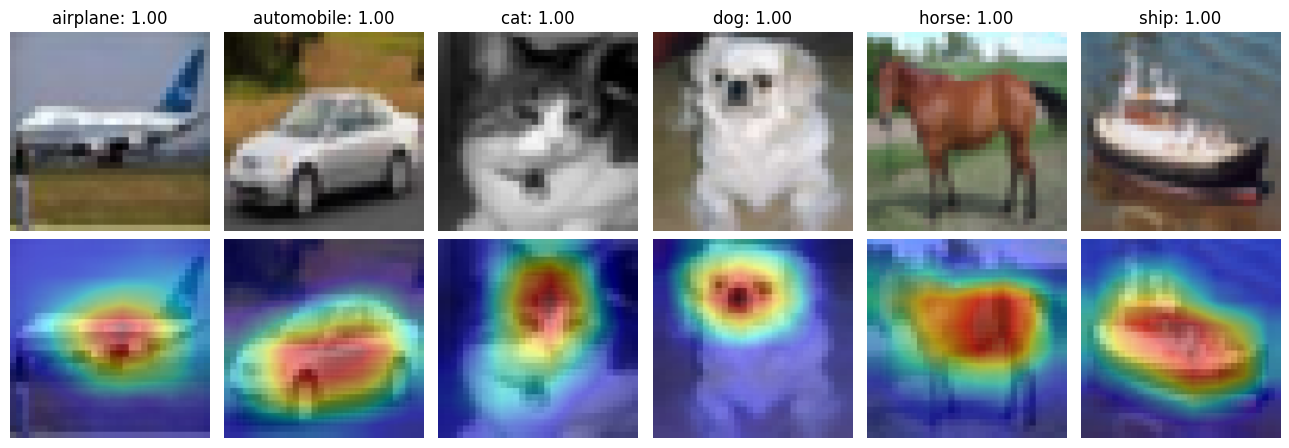

test images: [9890, 7876, 9388, 1650, 6534, 2574]


In [16]:
def cam(i, c):
    m = torch.einsum("k,khw->hw", W[c], feats[i])
    m = (m - m.min()) / (m.max() - m.min() + 1e-9)
    return F.interpolate(m[None, None], size=(128, 128), mode="bilinear", align_corners=False)[0, 0].numpy(), m.numpy()
def show(i):
    return np.asarray(torch.tensor(X[i]).permute(1, 2, 0).numpy().repeat(4, 0).repeat(4, 1))

want = ["airplane", "automobile", "cat", "dog", "horse", "ship"]
picks = []
for name in want:
    c = classes.index(name)
    ok = np.where((y == c) & (pred == c))[0]
    picks.append(ok[np.argsort(-P[ok, c].numpy())][5])
with plt.style.context("default"):
    fig, ax = plt.subplots(2, 6, figsize=(13, 4.6))
    for k, i in enumerate(picks):
        up, _ = cam(i, pred[i])
        ax[0, k].imshow(show(i)); ax[0, k].set_title(f"{classes[pred[i]]}: {P[i, pred[i]]:.2f}", fontsize=12)
        ax[1, k].imshow(show(i)); ax[1, k].imshow(up, cmap="jet", alpha=0.45)
    for a in ax.ravel(): a.axis("off")
    fig.tight_layout(); fig.savefig(f"{RESULTS}/gen_cam_cifar_correct.png", dpi=150); plt.show()
print("test images:", [int(i) for i in picks])

In all six images the map is large on the object and small on the sky, the road or the water around it: the network has learned to base its decisions on the objects, although it was trained only with class labels and never told where the objects are. The dog of this figure is the image of the numerical check. A second figure follows its map through the three operations: the $8\times8$ map with the values of equation (14), the map upsampled to the image size, and the overlay.

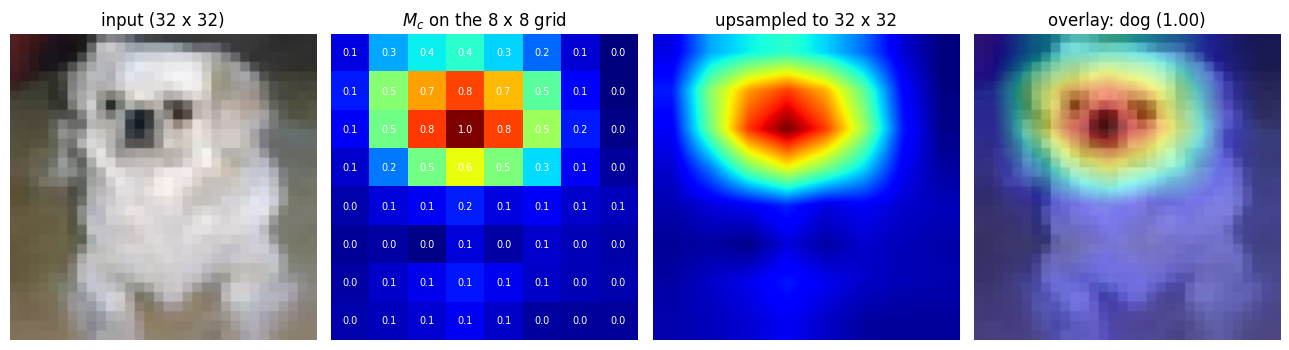

In [17]:
i = picks[3]; up, raw = cam(i, pred[i])
with plt.style.context("default"):
    fig, ax = plt.subplots(1, 4, figsize=(13, 3.5))
    ax[0].imshow(show(i)); ax[0].set_title("input (32 x 32)")
    ax[1].imshow(raw, cmap="jet"); ax[1].set_title(r"$M_c$ on the 8 x 8 grid")
    for r in range(8):
        for q in range(8): ax[1].text(q, r, f"{raw[r, q]:.1f}", ha="center", va="center", fontsize=7, color="w")
    ax[2].imshow(up, cmap="jet"); ax[2].set_title("upsampled to 32 x 32")
    ax[3].imshow(show(i)); ax[3].imshow(up, cmap="jet", alpha=0.45); ax[3].set_title(f"overlay: {classes[pred[i]]} ({P[i, pred[i]]:.2f})")
    for a in ax: a.axis("off")
    fig.tight_layout(); fig.savefig(f"{RESULTS}/gen_cam_cifar_steps.png", dpi=150); plt.show()

A map is most useful when the network is wrong. For three of the frequent confusions, a cat taken for a dog, a dog taken for a cat and an automobile taken for a truck, the figure shows the third most confident mistake with two maps: one for the predicted (wrong) class and one for the true class, each with the probability of its class.

misclassified 4617 cat -> dog 0.9574378728866577 0.02662249468266964
misclassified 9260 dog -> cat 0.941552996635437 0.05414301156997681
misclassified 3560 automobile -> truck 0.9697309136390686 0.03025370091199875


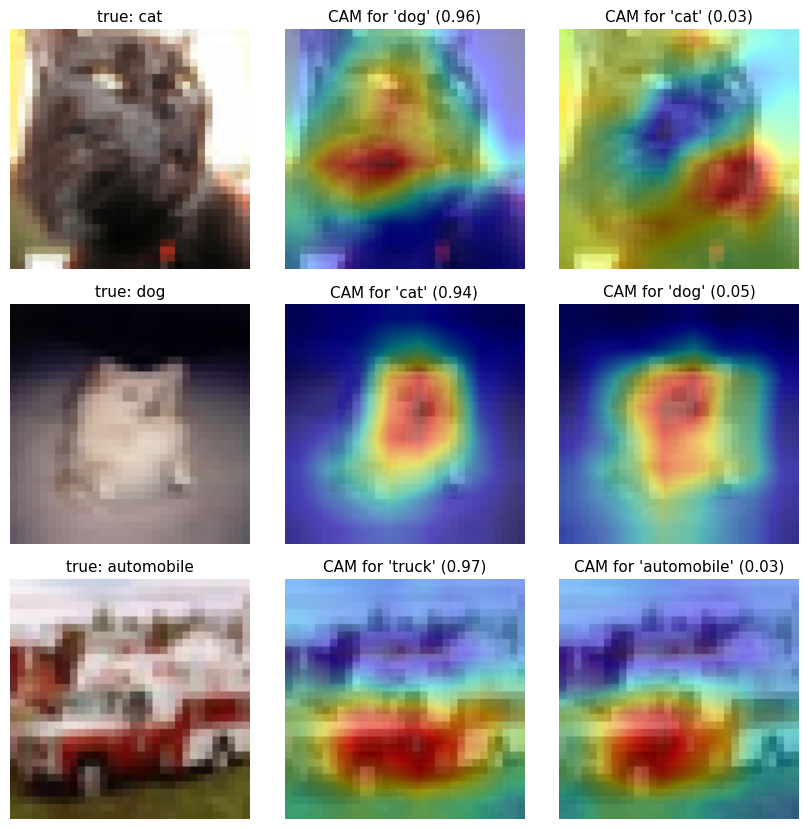

In [18]:
pairs = [("cat", "dog"), ("dog", "cat"), ("automobile", "truck")]
with plt.style.context("default"):
    fig, ax = plt.subplots(3, 3, figsize=(8.4, 8.4))
    for r, (true, wrong) in enumerate(pairs):
        t, w_ = classes.index(true), classes.index(wrong)
        cand = np.where((y == t) & (pred == w_))[0]
        i = cand[np.argsort(-P[cand, w_].numpy())][2]
        ax[r, 0].imshow(show(i)); ax[r, 0].set_title(f"true: {true}", fontsize=11)
        for col, c in [(1, w_), (2, t)]:
            up, _ = cam(i, c)
            ax[r, col].imshow(show(i)); ax[r, col].imshow(up, cmap="jet", alpha=0.45)
            ax[r, col].set_title(f"CAM for '{classes[c]}' ({P[i, c]:.2f})", fontsize=11)
        print("misclassified", i, true, "->", wrong, float(P[i, w_]), float(P[i, t]))
    for a in ax.ravel(): a.axis("off")
    fig.tight_layout(); fig.savefig(f"{RESULTS}/gen_cam_cifar_wrong.png", dpi=150); plt.show()

The maps show what the wrong decision was based on. When both maps cover the same region, the network looked at the right object and weighed its features wrongly; the maps of "cat" and "dog" overlap strongly, because the two classes share most of their features. The map cannot say why a feature was misleading, only where it was found.

## Figures on the slides

The figures saved in `results/` are compared with the files of the same names in `../beamer/figures/`. The comparison uses the decoded pixels, so that metadata inside the PNG files (portable network graphics) does not count. A file in the slide folder is replaced only if its pixels are identical; otherwise the difference is reported and the slide file is kept.

Three further slide files are cut out of these figures: the upper 382 pixel rows of `gen_cam_path_map.png` (without the axis label of the map), and the input panel and the overlay panel of `gen_cam_cifar_steps.png`. The pixel boxes $(x_0, y_0, x_1, y_1)$ are those of the files on the slides.

In [19]:
from PIL import Image as PILImage
CROPS = {"gen_cam_path_map_crop.png": ("gen_cam_path_map.png", (0, 0, 1950, 382), "RGBA"),
         "gen_cam_cifar_dog_input.png": ("gen_cam_cifar_steps.png", (23, 1, 483, 492), "RGBA"),
         "gen_cam_overlay_dog.png": ("gen_cam_cifar_steps.png", (1443, 33, 1928, 492), "RGB")}
for out, (src, box, mode) in CROPS.items():
    PILImage.open(f"{RESULTS}/{src}").convert(mode).crop(box).save(f"{RESULTS}/{out}")
    print(out, "from", src, box)

gen_cam_path_map_crop.png from gen_cam_path_map.png (0, 0, 1950, 382)
gen_cam_cifar_dog_input.png from gen_cam_cifar_steps.png (23, 1, 483, 492)
gen_cam_overlay_dog.png from gen_cam_cifar_steps.png (1443, 33, 1928, 492)


In [20]:
FIGS = ["gen_cam_cifar_correct.png", "gen_cam_cifar_steps.png", "gen_cam_cifar_wrong.png", "gen_cam_path_gap.png", "gen_cam_path_map.png",
        "gen_cam_path_map_crop.png", "gen_cam_cifar_dog_input.png", "gen_cam_overlay_dog.png"]
for name in FIGS:
    a = np.asarray(PILImage.open(f"{RESULTS}/{name}").convert("RGBA")).astype(int)
    p = f"{SLIDE_FIGS}/{name}"
    if not os.path.exists(p): print(f"{name:28s} no slide file"); continue
    b = np.asarray(PILImage.open(p).convert("RGBA")).astype(int)
    if a.shape != b.shape: print(f"{name:28s} DIFFERENT size: notebook {a.shape}, slides {b.shape}"); continue
    d = np.abs(a - b)
    same_bytes = open(f"{RESULTS}/{name}", "rb").read() == open(p, "rb").read()
    print(f"{name:28s} {a.shape[1]} x {a.shape[0]} px, pixels differing: {(d.max(-1) > 0).sum():6d}, "
          f"max difference {d.max():3d}, identical file: {same_bytes}")

gen_cam_cifar_correct.png    1950 x 690 px, pixels differing:      0, max difference   0, identical file: True
gen_cam_cifar_steps.png      1950 x 525 px, pixels differing:      0, max difference   0, identical file: True


gen_cam_cifar_wrong.png      1260 x 1260 px, pixels differing:      0, max difference   0, identical file: True
gen_cam_path_gap.png         1800 x 450 px, pixels differing:      0, max difference   0, identical file: True
gen_cam_path_map.png         1950 x 450 px, pixels differing:      0, max difference   0, identical file: True


gen_cam_path_map_crop.png    1950 x 382 px, pixels differing:      0, max difference   0, identical file: True
gen_cam_cifar_dog_input.png  460 x 491 px, pixels differing:      0, max difference   0, identical file: False
gen_cam_overlay_dog.png      485 x 459 px, pixels differing:      0, max difference   0, identical file: True


## Comparison with the GAP network of Lab 013a

Lab 013a trains a smaller network of the same kind, `GapCNN`: three convolutional layers ($3\to32\to64\to128$ channels, each followed by batch normalisation and ReLU, max pooling after the first two), global average pooling and a dense layer, $94\,986$ parameters in total. After 3 epochs it reaches $62.1\%$ training and $60.4\%$ test accuracy (stored outputs of Section 9 of `Lab_013a_CNN_on_MNIST_and_CIFAR10_PyTorch.ipynb`, printed again by the code that follows). The six-layer network reaches $87.6\%$. Both use batch normalisation, data augmentation and the Adam optimiser on all $50\,000$ training images; they differ in five respects.

- Depth: six convolutional layers instead of three, in blocks of two at each resolution, with $289\,194$ instead of $94\,986$ parameters. Two stacked $3\times3$ convolutions see a $5\times5$ neighbourhood, so each of the final $8\times8$ positions combines information from a larger part of the image, and the features before pooling are more complex.
- Batch normalisation after each of the six convolutions instead of three, which keeps the inputs of every layer on a common scale in the deeper network.
- Augmentation: in Lab 013a every image is mirrored with probability $1/2$ and shifted by its own random offset of up to 4 pixels with zero padding; here the shift is one per mini-batch with reflect padding. Lab 013a also adds L2 weight decay ($5\cdot10^{-4}$), which this network does not use.
- Schedule: a constant learning rate of $10^{-3}$ in Lab 013a, the one-cycle schedule of equation (7) with a maximum of $3\cdot10^{-3}$ here.
- Training length: 3 epochs (1173 steps) against 12 epochs (4692 steps).

The training log allows a comparison at equal length: after 3 epochs the deeper network had $67.2\%$ test accuracy, still in the rising phase of its schedule, against $60.4\%$ for the network of Lab 013a. The remaining twenty points come from the nine further epochs, most of them while the learning rate decreases. The maps of both networks are computed by the same equation (12).

In [21]:
import json
lab = json.load(open("Lab_013a_CNN_on_MNIST_and_CIFAR10_PyTorch.ipynb"))
for cell in lab["cells"]:
    src = "".join(cell["source"])
    if cell["cell_type"] == "code" and ("GapCNN()" in src or "GAP CNN: {count_params" in src):
        for o in cell.get("outputs", []):
            for line in "".join(o.get("text", "")).splitlines():
                if "GAP CNN" in line or line.startswith("parameters"): print("Lab 013a:", line)
print(f"six-layer network: {n_params} parameters, test accuracy {test_acc:.4f}; after 3 epochs (log) {LOG_TEST_ACC[2]:.3f}")

Lab 013a: parameters: 94986
Lab 013a: GAP CNN epoch 1/3: train acc 0.520, test acc 0.512, test loss 1.330  (134 s)
Lab 013a: GAP CNN epoch 2/3: train acc 0.604, test acc 0.595, test loss 1.136  (262 s)
Lab 013a: GAP CNN epoch 3/3: train acc 0.621, test acc 0.604, test loss 1.117  (363 s)
Lab 013a: GAP CNN: 94986 parameters, train acc 62.1%, test acc 60.4%
six-layer network: 289194 parameters, test accuracy 0.8756; after 3 epochs (log) 0.672


## Summary

The CIFAR-10 photographs, $32\times32$ RGB images in ten classes, are classified by a CNN with six convolutional layers, batch normalisation, global average pooling and one dense layer, $289\,194$ parameters. Trained for 12 epochs with data augmentation, Adam and a one-cycle learning-rate schedule, it reaches $87.56\%$ test accuracy, against $60.4\%$ for the three-layer GAP network of Lab 013a after 3 epochs. Its weakest class is the cat, and its most frequent error confuses cats with dogs.

Because the network ends with global average pooling and one dense layer, the class score of equation (9) equals the mean of the class activation map of equation (12) plus the bias, equation (13); this identity holds numerically. The maps of correctly classified images lie on the objects; for misclassified images, the maps of the predicted and of the true class show which regions the decision was based on. Every CAM figure of the lecture slides is reproduced from the stored parameters.